# 04 · Análisis de resultados

Este notebook analiza las **23 corridas** del diseño experimental (ver `src/triaje/experimentos.py`) a partir de `results/resultados.csv` y de las predicciones guardadas en `results/pred_*.jsonl`. Toda la lógica está en `src/triaje/analisis.py`; aquí solo se orquesta y se interpreta.

**Perspectivas del análisis**

1. Desempeño del modelo: línea base vs. LoRA.
2. Efecto de los hiperparámetros: ANOVA de dos factores con réplicas (r × α/r).
3. Rendimientos decrecientes: regresión vs. r y verificación fuera del dominio.
4. Reproducibilidad entre semillas.
5. Análisis de errores y seguridad clínica: qué campos y qué casos falla el modelo.
6. Comparación de tecnologías: LoRA vs. DoRA (fundamento y análisis objetivo).
7. Costo computacional: VRAM, tiempo de entrenamiento e inferencia.
8. Costo frente a herramientas de pago: fine-tuning por API, inferencia por token y GPU dedicada.
9. Conclusiones.

**Cómo ejecutarlo:** desde la raíz del repositorio (localmente) o en Colab después del `%cd triaje-clinico-lora`. No necesita GPU ni los adaptadores entrenados, solo `results/`. Las interpretaciones en texto corresponden a los resultados guardados en el repositorio.

In [1]:
# === Setup ===
# En Google Colab: clona la rama del proyecto, instala el paquete y monta Drive.
# Fuera de Colab (local, desde la raíz del repo) esta celda no hace nada.
import os, sys
EN_COLAB = "google.colab" in sys.modules
RAMA = "splits-con-manual"  # cambiar a "main" cuando la rama se fusione
if EN_COLAB:
    if not os.path.exists("/content/triaje-clinico-lora"):
        !git clone -q -b {RAMA} https://github.com/Hammonne/triaje-clinico-lora.git /content/triaje-clinico-lora
    %cd /content/triaje-clinico-lora
    !git pull -q
    # Colab trae torchao 0.10, que peft 0.21 rechaza (pide >= 0.16); no lo usamos.
    !pip uninstall -q -y torchao
    # Colab ya trae las dependencias: esto solo verifica versiones mínimas e instala `triaje`.
    !pip install -q -r requirements.txt
    !pip install -q -e .
    from google.colab import drive
    drive.mount("/content/drive")

In [2]:
# === Celda de configuración (única fuente de parámetros) ===
import sys; sys.path.insert(0, "src")
from pathlib import Path
from triaje.config import Config, set_seed

config = Config()
# Lee los resultados versionados en el repositorio (results/). Para analizar los de
# una corrida nueva guardada en Drive, apuntar ahí:
# config.results_dir = Path("/content/drive/MyDrive/triaje/results")
set_seed(config.seed)
print("modelo:", config.model_name, "| resultados en:", config.results_dir)

D:\Documents-D\UTEC\Planificacion\triaje-clinico-lora\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1023 23:31:11.324000 19856 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


modelo: Qwen/Qwen2.5-0.5B-Instruct | resultados en: results


## 0. Datos de los experimentos

Una fila por corrida. `tecnica = base` es el modelo sin adaptador.

In [3]:
from triaje import analisis as A
from IPython.display import Image, display
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
df = A.cargar_resultados(config.results_dir / "resultados.csv")
print(len(df), "corridas")
df[["run_id", "tecnica", "r", "alpha", "seed", "esquema_ok_post", "exact_match_categoricos",
    "f1_prioridad", "tasa_subtriaje", "segundos_entrenamiento", "vram_entrenamiento_gb"]]

23 corridas


,run_id,tecnica,r,alpha,seed,esquema_ok_post,exact_match_categoricos,f1_prioridad,tasa_subtriaje,segundos_entrenamiento,vram_entrenamiento_gb
0,base_s42,base,NaN,NaN,42,0.0178,0.0000,0.0051,0.5000,NaN,NaN
1,lora_r4_a4_s42,lora,4.0,4.0,42,0.9422,0.0667,0.1757,0.3632,269.87,5.414
2,dora_r16_a32_s42,dora,16.0,32.0,42,0.9733,0.1467,0.3472,0.2877,570.92,7.518
3,lora_r2_a4_s42,lora,2.0,4.0,42,0.9378,0.0622,0.1784,0.3697,257.06,5.385
4,lora_r128_a256_s42,lora,128.0,256.0,42,0.9956,0.1600,0.3963,0.2455,271.04,6.790
5,lora_r4_a8_s42,lora,4.0,8.0,42,0.9511,0.0756,0.2073,0.3505,263.31,5.407
6,lora_r16_a16_s42,lora,16.0,16.0,42,0.9733,0.0800,0.2095,0.3927,269.98,5.530
7,lora_r16_a32_s42,lora,16.0,32.0,42,0.9778,0.1422,0.3437,0.2864,265.90,5.532
8,lora_r64_a64_s42,lora,64.0,64.0,42,0.9867,0.1200,0.3112,0.3108,272.65,6.111
9,lora_r64_a128_s42,lora,64.0,128.0,42,0.9822,0.1422,0.3484,0.2624,263.15,6.096


### Métricas que usamos

- `esquema_ok_post` (JSON que cumple el esquema) **satura cerca de 1** con cualquier LoRA, así que distingue poco entre configuraciones. Sirve para comparar contra la línea base.
- **Métrica principal: `exact_match_categoricos`**, que exige acertar a la vez especialidad, prioridad, acción y grupo de edad. Es la más exigente y la que mejor refleja si el triaje completo es correcto.
- **`f1_prioridad`** (macro-F1): la prioridad es el campo crítico, y el macro-F1 pesa igual a cada nivel aunque la prioridad II sea minoritaria.
- **`tasa_subtriaje`**: proporción de casos a los que el modelo asigna una prioridad menos urgente que la real. Es el error clínicamente peligroso.

In [4]:
METRICA = "exact_match_categoricos"  # métrica principal
METRICAS = ["exact_match_categoricos", "f1_prioridad", "tasa_subtriaje", "esquema_ok_post"]

## 1. Desempeño: línea base vs. LoRA

Promedio de las 2 réplicas (semillas) por configuración.

In [5]:
cols = ["esquema_ok_post", "json_valido_post", "exact_match_categoricos", "acc_especialidad",
        "acc_prioridad", "acc_accion", "acc_grupo_edad", "f1_prioridad", "sintomas_f1", "tasa_subtriaje"]
df.groupby(["tecnica", "r", "ratio_alpha_r"], dropna=False)[cols].mean().round(3)

esquema_ok_post  json_valido_post  \
tecnica r     ratio_alpha_r                                      
base    NaN   NaN                      0.018             0.996   
dora    4.0   2.0                      0.960             0.989   
        16.0  2.0                      0.971             0.998   
        64.0  2.0                      0.987             1.000   
lora    2.0   2.0                      0.938             1.000   
        4.0   1.0                      0.933             0.998   
              2.0                      0.960             0.989   
        16.0  1.0                      0.976             0.998   
              2.0                      0.973             1.000   
        64.0  1.0                      0.987             1.000   
              2.0                      0.989             0.998   
        128.0 2.0                      0.998             1.000   

                             exact_match_categoricos  acc_especialidad  \
tecnica r     ratio_alpha_r                                              
base    NaN   NaN                              0.000             0.000   
dora    4.0   2.0                              0.073             0.560   
        16.0  2.0                              0.140             0.598   
        64.0  2.0                              0.138             0.640   
lora    2.0   2.0                              0.060             0.507   
        4.0   1.0                              0.056             0.491   
              2.0                              0.069             0.560   
        16.0  1.0                              0.076             0.578   
              2.0                              0.136             0.596   
        64.0  1.0                              0.131             0.622   
              2.0                              0.144             0.633   
        128.0 2.0                              0.142             0.644   

                             acc_prioridad  acc_accion  acc_grupo_edad  \
tecnica r     ratio_alpha_r                                              
base    NaN   NaN                    0.004       0.004           0.009   
dora    4.0   2.0                    0.418       0.269           0.478   
        16.0  2.0                    0.518       0.464           0.518   
        64.0  2.0                    0.487       0.444           0.549   
lora    2.0   2.0                    0.371       0.224           0.447   
        4.0   1.0                    0.362       0.222           0.442   
              2.0                    0.404       0.258           0.458   
        16.0  1.0                    0.424       0.284           0.487   
              2.0                    0.513       0.464           0.504   
        64.0  1.0                    0.502       0.411           0.533   
              2.0                    0.509       0.447           0.533   
        128.0 2.0                    0.491       0.458           0.549   

                             f1_prioridad  sintomas_f1  tasa_subtriaje  
tecnica r     ratio_alpha_r                                             
base    NaN   NaN                   0.005        0.093           0.500  
dora    4.0   2.0                   0.205        0.162           0.363  
        16.0  2.0                   0.356        0.218           0.272  
        64.0  2.0                   0.357        0.257           0.239  
lora    2.0   2.0                   0.176        0.137           0.372  
        4.0   1.0                   0.170        0.132           0.372  
              2.0                   0.197        0.153           0.372  
        16.0  1.0                   0.219        0.200           0.378  
              2.0                   0.355        0.216           0.269  
        64.0  1.0                   0.346        0.227           0.261  
              2.0                   0.372        0.251           0.236  
        128.0 2.0                   0.417        0.268           0.236

**Interpretación.**

- **Sin adaptador, el modelo no sirve para la tarea.** Produce JSON casi siempre (99,6%), pero solo el **1,8%** cumple el esquema: inventa clases que no existen, cambia tipos (por ejemplo, `sintomas` como texto) o agrega texto. Su acierto exacto es 0. Su tasa de sub-triaje (0,50) se calcula sobre ese 1,8% y no es comparable.
- **Con 100 pasos de LoRA, incluso con r = 2 (1,1 M de parámetros entrenables, 0,22% del modelo), el esquema válido sube a 94%** y el modelo aprende las clases. El formato es lo primero que se aprende y lo más barato.
- **La tarea clínica es mucho más difícil que el formato.** El mejor LoRA acierta la especialidad en ~64% de los casos, la prioridad en ~50% y el grupo de edad en ~55%, pero los cuatro campos a la vez solo en **~14%**. El error se compone: con cuatro campos de ~50–65% de acierto cada uno, acertar todos es raro.
- La ganancia es grande en términos relativos (de 0 a 14% de acierto exacto; F1 de prioridad de 0,005 a 0,42), pero el desempeño absoluto sigue siendo bajo para un uso clínico.

## 2. Efecto de los hiperparámetros: ANOVA de dos factores con réplicas

Diseño factorial LoRA: r ∈ {4, 16, 64} × α/r ∈ {1, 2}, 2 semillas por celda (12 corridas). Modelo `métrica ~ C(r) * C(α/r)`, suma de cuadrados tipo II. DoRA y los extremos (r = 2, 128) no entran al ANOVA.

In [6]:
for m in METRICAS:
    print(f"=== {m} ===")
    print(A.anova_dos_factores(df, "lora", m).round(4))
    print()

=== exact_match_categoricos ===


               sum_sq   df        F  PR(>F)
C(r)           0.0115  2.0  47.7072  0.0002
C(ratio)       0.0025  1.0  20.7930  0.0039
C(r):C(ratio)  0.0015  2.0   6.0198  0.0368
Residual       0.0007  6.0      NaN     NaN

=== f1_prioridad ===
               sum_sq   df        F  PR(>F)
C(r)           0.0622  2.0  44.4663  0.0003
C(ratio)       0.0120  1.0  17.1113  0.0061
C(r):C(ratio)  0.0080  2.0   5.7181  0.0407
Residual       0.0042  6.0      NaN     NaN

=== tasa_subtriaje ===
               sum_sq   df        F  PR(>F)
C(r)           0.0309  2.0  11.0292  0.0098
C(ratio)       0.0059  1.0   4.2063  0.0861
C(r):C(ratio)  0.0066  2.0   2.3484  0.1765
Residual       0.0084  6.0      NaN     NaN

=== esquema_ok_post ===
               sum_sq   df        F  PR(>F)
C(r)           0.0035  2.0  23.1786  0.0015
C(ratio)       0.0002  1.0   3.1243  0.1276
C(r):C(ratio)  0.0005  2.0   3.1879  0.1140
Residual       0.0005  6.0      NaN     NaN



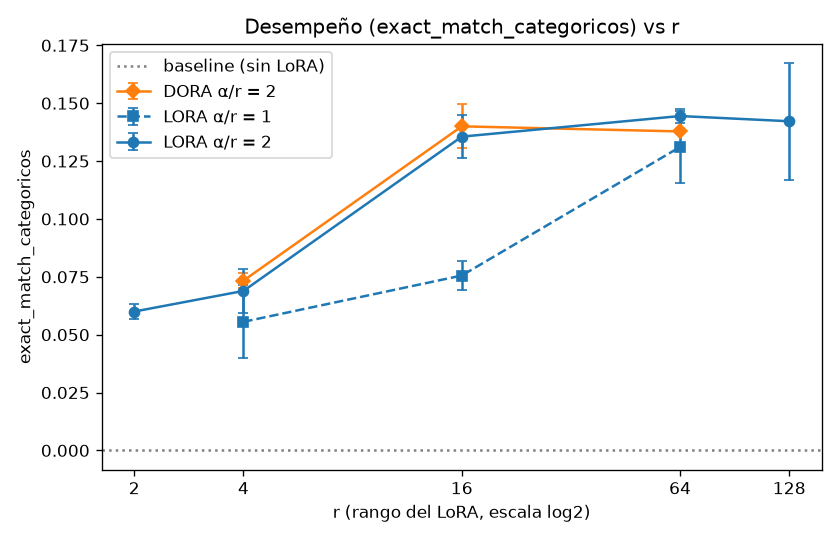

In [7]:
display(Image(filename=str(A.graficar_desempeno_vs_r(df, config.results_dir, METRICA))))

**Interpretación.**

- **r es el factor dominante** en las cuatro métricas (p ≤ 0,01): más rango, más capacidad del adaptador y mejor desempeño.
- **α/r también es significativo** en el acierto exacto (p = 0,004) y en el F1 de prioridad (p = 0,006), **y la interacción r × α/r también lo es** (p ≈ 0,04). En el gráfico se ve que las líneas no son paralelas:
  - con r = 16, pasar de α/r = 1 a α/r = 2 casi duplica el acierto exacto (0,076 → 0,136);
  - con r = 64 la diferencia casi desaparece (0,131 → 0,144).
- **Por qué:** la corrección LoRA se escala por α/r. Con solo 100 pasos, un adaptador de rango bajo y escala chica no alcanza a mover lo suficiente el modelo. Duplicar la escala compensa la falta de capacidad. Con r alto el adaptador ya tiene capacidad de sobra y la escala importa menos.
- **En el sub-triaje solo r es significativo** (α/r: p = 0,09): la seguridad clínica depende sobre todo de la capacidad del adaptador.
- **Cautela estadística:** con 2 réplicas por celda el error tiene solo 6 grados de libertad, así que los p-valores cercanos a 0,05 (la interacción) son evidencia moderada, no concluyente. Los efectos principales de r son muy robustos (F > 40).

## 3. Rendimientos decrecientes y verificación fuera del dominio

Se ajustan tres modelos del desempeño contra r usando **solo** el factorial (r ∈ {4, 16, 64}, promediando α/r): lineal, logarítmico (`y = a·ln(r) + b`) y polinomio de grado 2. Luego se compara lo que predice el modelo logarítmico con lo medido en los extremos **r = 2 y r = 128**, que quedan fuera del rango del ajuste.

In [8]:
regs = {}
for m in ["exact_match_categoricos", "f1_prioridad", "esquema_ok_post"]:
    regs[m] = reg = A.regresion_desempeno_vs_r(df, "lora", m)
    print(f"=== {m} ===")
    print("R2 por modelo:", {k: round(float(v), 3) for k, v in reg.r2.items()})
    print("Modelo log: y = a*ln(r) + b ->", {k: round(v, 4) for k, v in reg.coef_log.items()})
    print("r donde la mejora marginal cae bajo 0.001 por unidad de r:", round(reg.r_rendimientos_decrecientes, 1))
    print()

=== exact_match_categoricos ===
R2 por modelo: {'lineal': 0.835, 'log': 0.993, 'poly2': 1.0}
Modelo log: y = a*ln(r) + b -> {'a': 0.0272, 'b': 0.0263}
r donde la mejora marginal cae bajo 0.001 por unidad de r: 27.2

=== f1_prioridad ===
R2 por modelo: {'lineal': 0.822, 'log': 0.99, 'poly2': 1.0}
Modelo log: y = a*ln(r) + b -> {'a': 0.0633, 'b': 0.1009}
r donde la mejora marginal cae bajo 0.001 por unidad de r: 63.3

=== esquema_ok_post ===
R2 por modelo: {'lineal': 0.741, 'log': 0.961, 'poly2': 1.0}
Modelo log: y = a*ln(r) + b -> {'a': 0.0148, 'b': 0.9285}
r donde la mejora marginal cae bajo 0.001 por unidad de r: 14.8



In [9]:
# Predicción del modelo log en los extremos vs. lo medido (media ± d.e. de las 2 semillas).
extremos = df[(df["tecnica"] == "lora") & (df["r"].isin([2, 128]))]
filas = []
for m, reg in regs.items():
    real = extremos.groupby("r")[m].agg(["mean", "std"])
    real["prediccion_log"] = reg.coef_log["a"] * np.log(real.index.astype(float)) + reg.coef_log["b"]
    real["error"] = real["mean"] - real["prediccion_log"]
    real["metrica"] = m
    filas.append(real.reset_index())
pd.concat(filas).set_index(["metrica", "r"]).round(4)

mean     std  prediccion_log   error
metrica                 r                                            
exact_match_categoricos 2.0    0.0600  0.0031          0.0452  0.0148
                        128.0  0.1422  0.0252          0.1585 -0.0163
f1_prioridad            2.0    0.1763  0.0030          0.1448  0.0315
                        128.0  0.4166  0.0288          0.4079  0.0088
esquema_ok_post         2.0    0.9378  0.0000          0.9388 -0.0010
                        128.0  0.9978  0.0031          1.0005 -0.0027

**Interpretación.**

- **El modelo logarítmico describe bien la relación** (R² = 0,99 en acierto exacto y en F1 de prioridad, frente a 0,82–0,84 del lineal). Cada vez que se multiplica r por 4 se gana una cantidad parecida de desempeño, es decir, la mejora por unidad de r cae como 1/r. El polinomio de grado 2 da R² = 1, pero con 3 puntos y 3 parámetros siempre ajusta perfecto. No sirve para elegir modelo y tampoco para extrapolar.
- **Punto de rendimientos decrecientes:** la mejora marginal cae bajo 0,001 por unidad de r en **r ≈ 27** para el acierto exacto y en **r ≈ 63** para el F1 de prioridad.
- **Verificación fuera del dominio (lo que pide la rúbrica):**
  - **r = 128:** el acierto exacto medido (0,142) queda **por debajo** de lo predicho (0,159) e incluso igual al de r = 64 (0,144). **La saturación es más fuerte de lo que supone la curva logarítmica.** Pasado r ≈ 64, duplicar el rango no mejora nada, aunque cuesta 0,7 GB más de VRAM y el doble de parámetros entrenables (35 M → 70 M). El F1 de prioridad sí sigue la predicción (0,417 medido frente a 0,408): ese campo todavía saca algo de provecho del rango extra, pero la varianza entre semillas en r = 128 es la más alta del diseño (d.e. 0,025–0,029).
  - **r = 2:** el modelo log **subestima** el desempeño (0,060 frente a 0,045). Incluso un adaptador mínimo aprende el formato y algo de la tarea.
- **Conclusión:** la frontera donde el LoRA deja de mejorar está **entre r = 16 y r = 64**. Por encima de ese punto se paga más VRAM y más parámetros por mejoras que caben dentro del ruido entre semillas.

## 4. Reproducibilidad entre semillas

Coeficiente de variación (d.e. / media) del acierto exacto entre las 2 réplicas de cada configuración, y relación entre la *loss* final de entrenamiento y el desempeño en el test.

In [10]:
A.variabilidad_semillas(df, METRICA).round(3)

mean    std  count     cv
tecnica r     alpha                            
dora    4.0   8.0    0.073  0.003      2  0.043
        16.0  32.0   0.140  0.009      2  0.068
        64.0  128.0  0.138  0.000      2  0.000
lora    2.0   4.0    0.060  0.003      2  0.052
        4.0   4.0    0.056  0.016      2  0.284
              8.0    0.069  0.009      2  0.138
        16.0  16.0   0.076  0.006      2  0.083
              32.0   0.136  0.009      2  0.069
        64.0  64.0   0.131  0.016      2  0.120
              128.0  0.144  0.003      2  0.022
        128.0 256.0  0.142  0.025      2  0.177

In [11]:
# ¿La loss de entrenamiento anticipa el desempeño en el test? (corridas con adaptador)
df.loc[~df["es_baseline"], ["loss_final", "exact_match_categoricos", "f1_prioridad", "tasa_subtriaje"]].corr().round(3)

,loss_final,exact_match_categoricos,f1_prioridad,tasa_subtriaje
loss_final,1.000,-0.921,-0.928,0.848
exact_match_categoricos,-0.921,1.000,0.947,-0.905
f1_prioridad,-0.928,0.947,1.000,-0.959
tasa_subtriaje,0.848,-0.905,-0.959,1.000


**Interpretación.**

- **La mayoría de las configuraciones son reproducibles**: el CV del acierto exacto va de 0 a 14%. Las dos excepciones son r = 4 con α/r = 1 (28%), la configuración más débil, donde el modelo está en el límite de aprender la tarea y la semilla decide más, y r = 128 (18%), donde el adaptador grande tiene más grados de libertad para converger a soluciones distintas.
- Esta variabilidad explica por qué hacían falta las réplicas. Con una sola semilla, la diferencia entre r = 64 y r = 128 (0,144 frente a 0,142) se podría haber leído en cualquier dirección.
- **La loss final anticipa bien el desempeño** (correlación de −0,92 con el acierto exacto y de −0,93 con el F1 de prioridad). Es una señal barata para descartar configuraciones malas antes de evaluar el test completo. La loss incluye el prompt del sistema, que es idéntico en todos los ejemplos, así que su valor absoluto no se puede comparar con la dificultad de la tarea.

## 5. Análisis de errores y seguridad clínica

Se analizan las predicciones de la mejor configuración por acierto exacto, **LoRA r = 64, α/r = 2**, juntando sus dos réplicas (450 predicciones; las inválidas no tienen campos y se excluyen). Esta sección mira qué casos falla el modelo y si esos errores son peligrosos, más allá de cuántos son.

In [12]:
mejor = ["lora_r64_a128_s42", "lora_r64_a128_s123"]
preds = sum((A.cargar_predicciones(config.results_dir, rid) for rid in mejor), [])
print("Predicciones con esquema válido:", sum(1 for p in preds if p["prediccion_parseada"]), "de", len(preds))
A.matriz_confusion_prioridad(preds)

Predicciones con esquema válido: 445 de 450


predicha,I,II,III,IV
real,,,,
I,24,50,29,1
II,6,19,25,0
III,2,40,108,0
IV,0,4,59,78


In [13]:
# Sub-triaje según la prioridad REAL: la tasa global mezcla casos que no se pueden sub-triar (IV).
A.subtriaje_por_nivel(preds).round(3)

,casos,sub_triados,tasa_subtriaje
prioridad_real,,,
I,104,80,0.769
II,50,25,0.500
III,150,0,0.000
IV,141,0,0.000


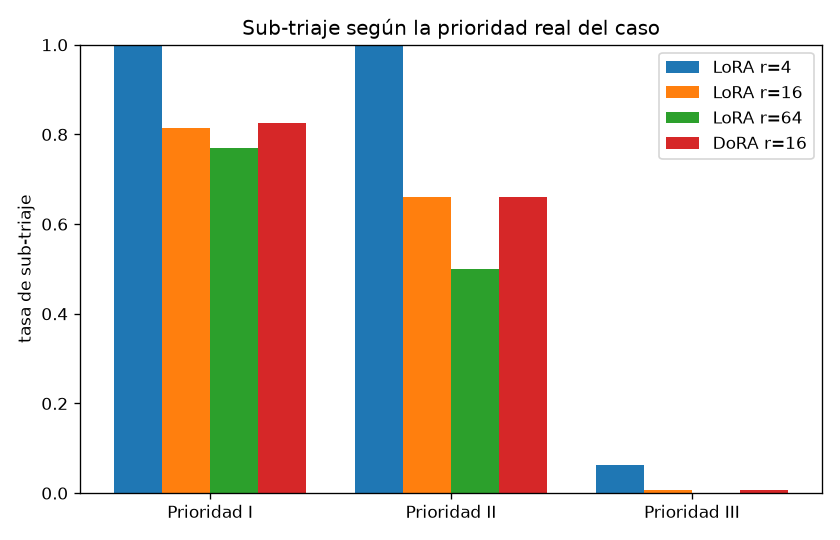

In [14]:
configs = {"LoRA r=4": ["lora_r4_a8_s42", "lora_r4_a8_s123"],
           "LoRA r=16": ["lora_r16_a32_s42", "lora_r16_a32_s123"],
           "LoRA r=64": ["lora_r64_a128_s42", "lora_r64_a128_s123"],
           "DoRA r=16": ["dora_r16_a32_s42", "dora_r16_a32_s123"]}
display(Image(filename=str(A.graficar_subtriaje_por_nivel(config.results_dir, configs))))

In [15]:
# Las confusiones más frecuentes de cada campo y la detección de signos de alarma.
for campo in ["prioridad", "accion", "grupo_edad", "especialidad"]:
    print(f"=== {campo} ===")
    print(A.confusiones_frecuentes(preds, campo, top=4).round(3).to_string(index=False))
    print()
print("Signos de alarma:", {k: round(v, 3) for k, v in A.metricas_signos_alarma(preds).items()})

=== prioridad ===
real predicho  casos  pct_de_validas
  IV      III     59           0.133
   I       II     50           0.112
 III       II     40           0.090
   I      III     29           0.065

=== accion ===
                real           predicho  casos  pct_de_validas
     cita_programada atencion_mismo_dia     95           0.213
emergencia_inmediata atencion_mismo_dia     93           0.209
     cita_programada orientacion_remota      8           0.018
  orientacion_remota atencion_mismo_dia      7           0.016

=== grupo_edad ===
           real     predicho  casos  pct_de_validas
no_especificado       adulto    102           0.229
    adolescente       adulto     20           0.045
   adulto_mayor       adulto     19           0.043
         adulto adulto_mayor     17           0.038

=== especialidad ===
            real             predicho  casos  pct_de_validas
medicina_general          cardiologia     18           0.040
medicina_general otorrinolaringologia     

**Interpretación.** Este es el hallazgo más importante del análisis.

- **La tasa global de sub-triaje (24%) esconde dónde está el peligro.** Todo el sub-triaje se concentra en los casos urgentes. El mejor modelo sub-tría el **77% de los casos de prioridad I** (80 de 104) y el **50% de los de prioridad II**, mientras que en III y IV no comete ninguno. Una emergencia con riesgo vital tiene más probabilidad de ser clasificada como menos urgente que de ser reconocida.
- **El modelo tiende hacia la prioridad III.** La matriz de confusión muestra que los errores van casi siempre hacia el centro: I → II/III y IV → III. Con r = 4 el modelo directamente **nunca predice I ni II** (sub-triaje del 100% en ambos niveles). Subir r es lo que le permite empezar a usar las prioridades urgentes, y por eso r es el único factor significativo en el sub-triaje.
- **La acción hereda el mismo sesgo:** la confusión dominante es predecir `atencion_mismo_dia` cuando correspondía `emergencia_inmediata` (~21% de las predicciones válidas) o `cita_programada` (~21%). El modelo elige la opción "del medio".
- **Grupo de edad:** el error más común es asumir `adulto` cuando el mensaje no da ninguna pista de edad (`no_especificado`). El modelo rellena con el valor más probable en vez de abstenerse.
- **Especialidad:** los errores son sobre todo consultas generales enviadas a una especialidad (`medicina_general` → cardiología, neurología u otorrino). Es un error de menor gravedad clínica.
- **Signos de alarma:** sensibilidad de solo ~58%. El modelo no detecta 4 de cada 10 casos con alarma, lo que es coherente con el sub-triaje de la prioridad I.
- **Posible causa: el cambio de dominio entre entrenamiento y prueba.** El entrenamiento es 94% sintético (1 050 ejemplos con 62 manuales) y el test es 97% manual (219 de 225). Las prioridades I y II no son raras en el entrenamiento (34% de los ejemplos), pero en el sintético salen de un banco de casos acotado y con frases típicas. Las urgencias escritas a mano por el equipo son más variadas, con jerga, familiares y urgencias escondidas. Es una hipótesis: no medimos el desempeño sobre un test sintético equivalente.

## 6. Comparación de tecnologías: LoRA vs. DoRA

### Fundamento

**LoRA** congela el peso preentrenado $W_0 \in \mathbb{R}^{d \times k}$ y aprende una corrección de bajo rango:

$$W' = W_0 + \frac{\alpha}{r} B A, \qquad B \in \mathbb{R}^{d \times r},\ A \in \mathbb{R}^{r \times k},\ r \ll \min(d, k)$$

**DoRA** (*Weight-Decomposed Low-Rank Adaptation*, Liu et al., 2024) descompone cada peso en una **magnitud** (la norma de cada columna) y una **dirección** (la matriz normalizada), y las entrena por separado:

$$W' = m \cdot \frac{W_0 + \frac{\alpha}{r} B A}{\lVert W_0 + \frac{\alpha}{r} B A \rVert_c}$$

donde $m \in \mathbb{R}^{1 \times k}$ es un vector de magnitudes entrenable (se inicializa con $\lVert W_0 \rVert_c$) y $\lVert \cdot \rVert_c$ es la norma por columna. La dirección se adapta con el mismo LoRA ($BA$) y la magnitud con $m$.

La motivación del paper es que el fine-tuning completo ajusta magnitud y dirección de forma bastante independiente, mientras que en LoRA ambas quedan acopladas en la misma actualización $BA$. Al separarlas, DoRA busca un patrón de aprendizaje más parecido al fine-tuning completo. Los autores reportan mejoras sobre LoRA con el mismo r, sobre todo con rangos bajos.

### Por qué elegimos DoRA

- **Está implementada en PEFT** (`LoraConfig(use_dora=True)`), como sugiere el enunciado. Usa exactamente los mismos hiperparámetros (r, α, capas), así que la comparación es controlada: solo cambia la técnica.
- **Plantea una hipótesis concreta y comprobable:** que con el mismo rango supera a LoRA, en especial con r bajo. Por eso la corrimos en r = 4, 16 y 64.
- **Agrega muy pocos parámetros** (el vector $m$, ~0,3 M), así que cualquier diferencia de desempeño no se puede atribuir a más capacidad.
- **Costo esperado:** calcular la norma de $W_0 + BA$ en cada paso hacia adelante agrega cómputo y memoria. Medir si ese costo compensa es parte de la comparación.

### Resultados

In [16]:
comp = df[(df["ratio_alpha_r"] == 2) & (df["r"].isin([4, 16, 64])) & (df["tecnica"].isin(["lora", "dora"]))]
cols = ["exact_match_categoricos", "f1_prioridad", "tasa_subtriaje", "esquema_ok_post",
        "segundos_entrenamiento", "vram_entrenamiento_gb", "segundos_por_ejemplo", "parametros_entrenables"]
comp.groupby(["r", "tecnica"])[cols].agg(["mean", "std"]).round(4)

exact_match_categoricos         f1_prioridad          \
                                mean     std         mean     std   
r    tecnica                                                        
4.0  dora                     0.0734  0.0032       0.2049  0.0074   
     lora                     0.0689  0.0095       0.1973  0.0141   
16.0 dora                     0.1400  0.0095       0.3560  0.0125   
     lora                     0.1356  0.0094       0.3548  0.0157   
64.0 dora                     0.1378  0.0000       0.3569  0.0344   
     lora                     0.1444  0.0032       0.3716  0.0328   

             tasa_subtriaje         esquema_ok_post          \
                       mean     std            mean     std   
r    tecnica                                                  
4.0  dora            0.3633  0.0181          0.9600  0.0126   
     lora            0.3725  0.0311          0.9600  0.0126   
16.0 dora            0.2723  0.0218          0.9711  0.0031   
     lora            0.2694  0.0241          0.9734  0.0063   
64.0 dora            0.2388  0.0446          0.9867  0.0000   
     lora            0.2361  0.0372          0.9889  0.0095   

             segundos_entrenamiento         vram_entrenamiento_gb          \
                               mean     std                  mean     std   
r    tecnica                                                                
4.0  dora                   556.390  0.7495                7.4205  0.0431   
     lora                   261.335  2.7931                5.4415  0.0488   
16.0 dora                   576.825  8.3509                7.5455  0.0389   
     lora                   262.370  4.9922                5.5615  0.0417   
64.0 dora                   563.110  0.0707                8.1005  0.0431   
     lora                   264.255  1.5627                6.1200  0.0339   

             segundos_por_ejemplo         parametros_entrenables       
                             mean     std                   mean  std  
r    tecnica                                                           
4.0  dora                  0.9712  0.0018              2503680.0  0.0  
     lora                  0.5290  0.0006              2199552.0  0.0  
16.0 dora                  1.0203  0.0173              9102336.0  0.0  
     lora                  0.5310  0.0141              8798208.0  0.0  
64.0 dora                  1.0507  0.0079             35496960.0  0.0  
     lora                  0.5326  0.0023             35192832.0  0.0

In [17]:
# ANOVA técnica × r (α/r = 2, r ∈ {4, 16, 64}, 2 semillas): ¿DoRA cambia algo respecto de LoRA?
for m in ["exact_match_categoricos", "f1_prioridad", "tasa_subtriaje", "segundos_entrenamiento", "vram_entrenamiento_gb"]:
    print(f"=== {m} ===")
    print(A.anova_tecnica_por_r(df, m).round(4))
    print()

=== exact_match_categoricos ===
                 sum_sq   df         F  PR(>F)
C(tecnica)       0.0000  1.0    0.0351  0.8575
C(r)             0.0125  2.0  129.7940  0.0000
C(tecnica):C(r)  0.0001  2.0    0.8549  0.4713
Residual         0.0003  6.0       NaN     NaN

=== f1_prioridad ===
                 sum_sq   df        F  PR(>F)
C(tecnica)       0.0000  1.0   0.0235  0.8832
C(r)             0.0673  2.0  69.3226  0.0001
C(tecnica):C(r)  0.0003  2.0   0.2717  0.7710
Residual         0.0029  6.0      NaN     NaN

=== tasa_subtriaje ===
                 sum_sq   df        F  PR(>F)
C(tecnica)       0.0000  1.0   0.0045  0.9485
C(r)             0.0368  2.0  19.2559  0.0024
C(tecnica):C(r)  0.0001  2.0   0.0503  0.9513
Residual         0.0057  6.0      NaN     NaN

=== segundos_entrenamiento ===
                      sum_sq   df           F  PR(>F)
C(tecnica)       275042.3244  1.0  15646.6742  0.0000
C(r)                231.2798  2.0      6.5786  0.0307
C(tecnica):C(r)     211.3867  2.0

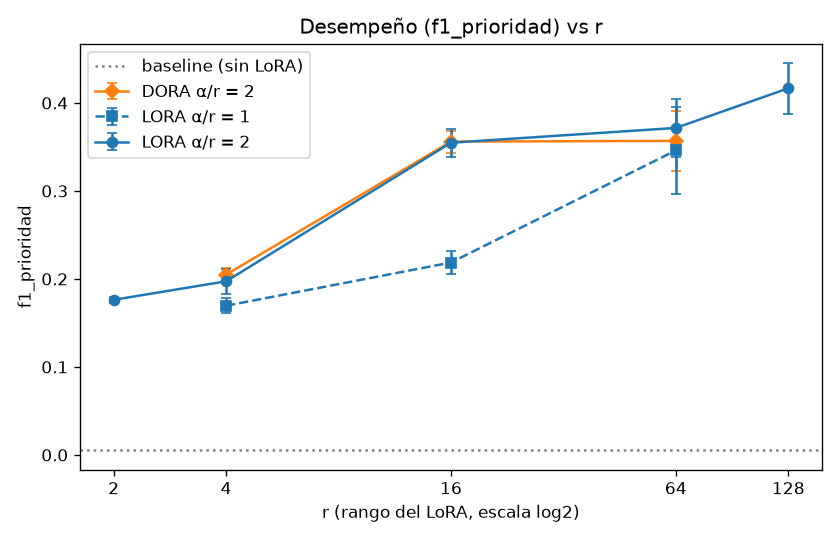

In [18]:
display(Image(filename=str(A.graficar_desempeno_vs_r(df, config.results_dir, "f1_prioridad"))))

**Análisis objetivo.**

- **En desempeño, DoRA y LoRA son estadísticamente indistinguibles.** En el ANOVA técnica × r, el factor técnica tiene p = 0,86 en acierto exacto, p = 0,88 en F1 de prioridad y p = 0,95 en sub-triaje, y la interacción técnica × r tampoco es significativa (p ≥ 0,47). DoRA sigue la misma curva de saturación que LoRA: las diferencias por r (±0,005 en acierto exacto) son menores que la variación entre semillas, y van en direcciones distintas (DoRA apenas arriba en r = 4 y 16, apenas abajo en r = 64).
- **La ventaja con rango bajo que reporta el paper no aparece aquí.** En r = 4, DoRA obtiene 0,073 de acierto exacto frente a 0,069 de LoRA, dentro del ruido. Con las prioridades urgentes tiene el mismo sesgo (sub-triaje de 83% en prioridad I con r = 16, frente a 82% de LoRA).
- **En costo, en cambio, la diferencia es enorme y muy significativa** (p < 0,0001):
  - **entrenamiento ~2,1–2,2× más lento** (556–577 s frente a 261–264 s);
  - **~2 GB más de VRAM** en todos los r (+35%), por las normas por columna y sus activaciones;
  - **inferencia ~1,9× más lenta** (0,97–1,05 s por ejemplo frente a 0,53 s).
- **Matiz sobre la inferencia:** medimos el modelo con el adaptador sin fusionar, como lo deja PEFT tras entrenar. Tanto LoRA como DoRA se pueden fusionar con los pesos base (`merge_and_unload`) para servir el modelo. Así la sobrecarga de inferencia de ambos desaparece. La diferencia en el costo de entrenamiento no se puede evitar.
- **Lectura:** el beneficio de DoRA depende del modelo y de la tarea. Aquí el cuello de botella no parece ser cómo se reparte la actualización entre magnitud y dirección, sino los datos (cambio de dominio sintético → manual) y la capacidad de un modelo de 0,5B. En esas condiciones, la flexibilidad extra de DoRA no tiene qué aprovechar.
- **Veredicto: para este modelo y esta tarea, DoRA no compensa su costo.** LoRA logra el mismo desempeño a menos de la mitad del tiempo y con 2 GB menos de VRAM.

## 7. Costo computacional

VRAM pico, tiempo de entrenamiento y costo simulado de cada corrida (T4 a 0,35 USD/h, supuesto configurable en `Config`).

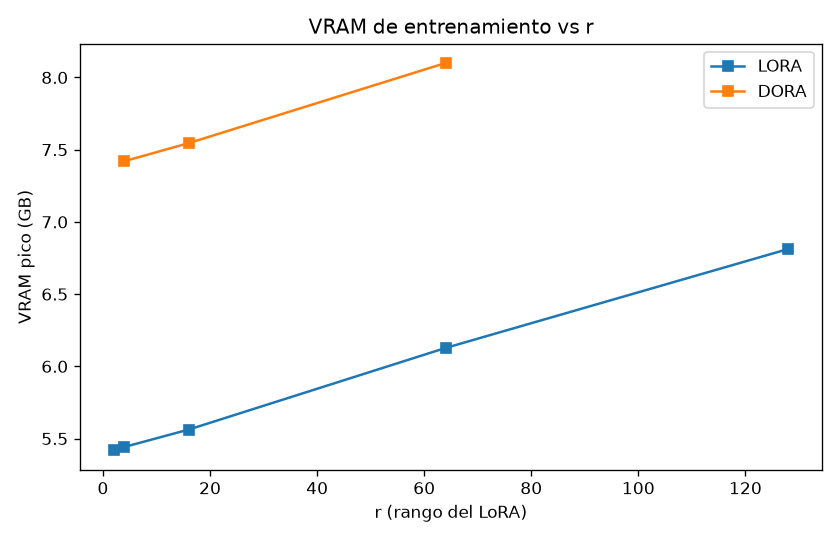

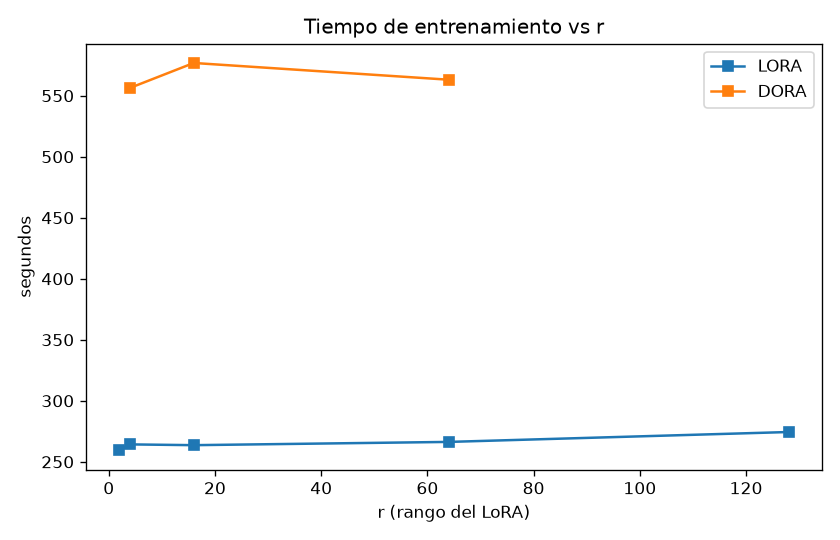

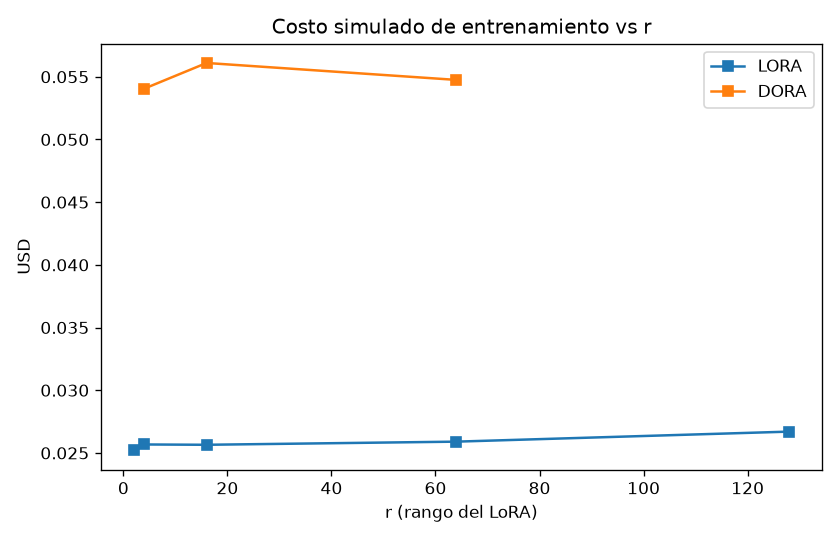

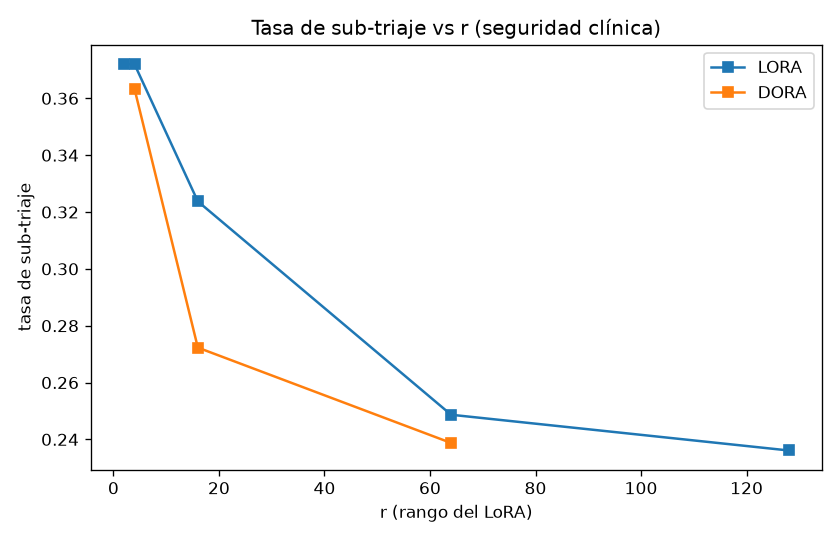

In [19]:
rutas = A.generar_todos_los_graficos(df, config.results_dir, METRICA)
for r in rutas[1:]:
    display(Image(filename=str(r)))

In [20]:
costo = df[~df["es_baseline"]].groupby(["tecnica", "r"])[
    ["parametros_entrenables", "vram_entrenamiento_gb", "segundos_entrenamiento", "segundos_por_ejemplo", "costo_usd"]
].mean()
# Eficiencia: acierto exacto por GB de VRAM de entrenamiento.
costo["exact_match_por_gb"] = (
    df[~df["es_baseline"]].groupby(["tecnica", "r"])["exact_match_categoricos"].mean() / costo["vram_entrenamiento_gb"]
)
n_test = 225  # ejemplos del test (data/splits/test.jsonl)
print("GPU de toda la suite: %.2f h de entrenamiento + %.2f h de inferencia" % (
    df["segundos_entrenamiento"].sum() / 3600, (df["segundos_por_ejemplo"] * n_test).sum() / 3600))
costo.round(4)

GPU de toda la suite: 2.12 h de entrenamiento + 0.93 h de inferencia


parametros_entrenables  vram_entrenamiento_gb  \
tecnica r                                                      
dora    4.0                 2503680.0                 7.4205   
        16.0                9102336.0                 7.5455   
        64.0               35496960.0                 8.1005   
lora    2.0                 1099776.0                 5.4180   
        4.0                 2199552.0                 5.4420   
        16.0                8798208.0                 5.5623   
        64.0               35192832.0                 6.1275   
        128.0              70385664.0                 6.8125   

               segundos_entrenamiento  segundos_por_ejemplo  costo_usd  \
tecnica r                                                                
dora    4.0                  556.3900                0.9712     0.0540   
        16.0                 576.8250                1.0203     0.0561   
        64.0                 563.1100                1.0507     0.0548   
lora    2.0                  259.3200                0.5210     0.0252   
        4.0                  264.2600                0.5211     0.0257   
        16.0                 263.6250                0.5354     0.0256   
        64.0                 266.2925                0.5355     0.0259   
        128.0                274.4000                0.5448     0.0267   

               exact_match_por_gb  
tecnica r                          
dora    4.0                0.0099  
        16.0               0.0186  
        64.0               0.0170  
lora    2.0                0.0111  
        4.0                0.0114  
        16.0               0.0190  
        64.0               0.0225  
        128.0              0.0209

**Interpretación.**

- **El tiempo de entrenamiento de LoRA casi no depende de r** (259–274 s entre r = 2 y r = 128). Con un modelo de 0,5B, el costo lo domina el paso por el modelo base congelado, no el adaptador. Subir r es casi gratis en tiempo.
- **La VRAM sí crece con r**, pero poco: de 5,4 GB (r = 2) a 6,8 GB (r = 128), porque los parámetros entrenables pasan de 1,1 M a 70 M y el optimizador guarda dos estados por parámetro. Todas las configuraciones caben holgadas en los 16 GB de la T4, incluida DoRA (máximo 8,1 GB).
- **Eficiencia:** el acierto exacto por GB de VRAM es máximo en r = 16–64. Por encima de r = 64 se paga VRAM sin ganancia, que es la misma frontera de la sección 3, ahora vista desde el costo.
- **Toda la suite (23 corridas) usó ~2,1 h de entrenamiento y ~0,9 h de inferencia** en una T4. Cada corrida LoRA tarda ~6,5 min y cada DoRA ~13,5 min. Haber elegido un modelo de 0,5B en lugar de uno de 3,8B (Phi-3.5) es lo que permitió hacer el diseño completo con réplicas dentro del presupuesto de Colab.

## 8. Costo frente a herramientas de pago

Simulamos tres decisiones de negocio con los **tokens medidos** (prompt real con el esquema y salidas reales del modelo) y precios **supuestos** configurables en `Config`:

| Supuesto | Valor |
| --- | --- |
| GPU T4 alquilada | 0,35 USD/h |
| API de inferencia | 0,15 USD por 1M tokens de entrada, 0,60 USD por 1M de salida |
| Servicio de fine-tuning por API | 3,00 USD por 1M tokens de entrenamiento |
| Mes de GPU dedicada 24/7 | 730 h |

Se usa la configuración recomendada, **LoRA r = 16, α/r = 2**.

In [21]:
# Tokens reales: prompt de inferencia (system prompt con el esquema + mensaje) y secuencias de entrenamiento.
from transformers import AutoTokenizer
from triaje.data import cargar_split
from triaje.evaluate import _texto_entrada
from triaje.train import _texto_entrenamiento
import json

tok = AutoTokenizer.from_pretrained(config.model_name)
test = cargar_split(config.data_dir / "splits", "test")
train = cargar_split(config.data_dir / "splits", "train")
tokens_in = np.mean([len(tok(_texto_entrada(e.mensaje, tok)).input_ids) for e in test])
tokens_train_ej = np.mean([len(tok(_texto_entrenamiento(e, tok, config)).input_ids) for e in train])

# Tokens de salida: tokens generados / ejemplos, del detalle de la corrida.
m = json.load(open(config.results_dir / "detalle_lora_r16_a32_s42.json", encoding="utf-8"))["metricas"]
tokens_out = m["tokens_por_segundo"] * m["segundos_inferencia_total"] / m["n"]

# Tokens procesados en un entrenamiento: pasos × batch efectivo × largo medio de secuencia.
batch_efectivo = config.per_device_train_batch_size * config.gradient_accumulation_steps
tokens_entrenamiento = config.max_steps * batch_efectivo * tokens_train_ej
print(f"tokens de entrada por mensaje: {tokens_in:.0f} | de salida: {tokens_out:.0f} | "
      f"de un entrenamiento: {tokens_entrenamiento:,.0f}")

tokens de entrada por mensaje: 398 | de salida: 90 | de un entrenamiento: 772,379


In [22]:
esc = A.escenarios_costo(
    df, "lora_r16_a32_s42", tokens_in, tokens_out, tokens_entrenamiento,
    precio_gpu_hora=config.precio_gpu_usd_hora,
    precio_api_in_1m=config.precio_api_usd_por_1m_tokens_in,
    precio_api_out_1m=config.precio_api_usd_por_1m_tokens_out,
    precio_finetuning_1m=config.precio_api_finetuning_usd_por_1m_tokens,
    horas_mes=config.horas_mes,
)
pd.Series(esc).round(4)

entrenar_lora_gpu_usd          2.590000e-02
entrenar_finetuning_api_usd    2.317100e+00
inferencia_gpu_por_1000_usd    5.260000e-02
inferencia_api_por_1000_usd    1.137000e-01
gpu_dedicada_mes_usd           2.555000e+02
capacidad_gpu_mensajes_mes     4.857671e+06
equilibrio_mensajes_mes        2.246338e+06
dtype: float64

**Interpretación.**

- **Entrenar:** nuestro LoRA cuesta **~0,026 USD** en una T4 alquilada (4,4 min). Procesar los mismos ~770 mil tokens en un servicio de fine-tuning de pago costaría **~2,3 USD**, unas **90 veces más**. Incluso la suite completa de 23 corridas (~0,8 USD de GPU) sale más barata que un solo fine-tuning por API. Experimentar con LoRA propio es prácticamente gratis frente a la alternativa de pago.
- **Inferencia por mensaje:** cada mensaje tiene ~400 tokens de entrada (el prompt incluye el esquema completo) y ~90 de salida.
  - **Con GPU por demanda:** ~0,053 USD por 1000 mensajes, porque la generación en lotes de 16 da 0,53 s por mensaje.
  - **Con la API supuesta:** ~0,114 USD por 1000 mensajes. Pagando solo las horas de GPU que se usan, el modelo propio cuesta **la mitad** que la API.
- **GPU dedicada 24/7:** cuesta ~255 USD al mes sin importar el volumen. Solo conviene frente a la API a partir de **~2,2 millones de mensajes al mes**, y a esa velocidad una T4 alcanza a atender ~4,9 millones. **Para una clínica con poco volumen, la API por token o una GPU encendida solo cuando hace falta salen más baratas que un servidor fijo.**
- **Lo que esta comparación no dice:** no medimos la calidad de una API comercial en esta tarea. Un modelo grande por API probablemente acierte más que nuestro modelo de 0,5B, y en triaje un error cuesta más que la diferencia de centavos. El argumento de costo a favor del LoRA propio solo vale si su calidad alcanza el mínimo clínico, y hoy no lo alcanza (sección 5). Los precios son supuestos, no cotizaciones.

## 9. Conclusiones

1. **LoRA es indispensable con un modelo pequeño.** Sin adaptador, Qwen2.5-0.5B no produce salidas utilizables (1,8% de esquema válido). Con 100 pasos de LoRA llega a 92–100% de esquema válido y aprende las clases, por ~0,03 USD de GPU.
2. **El rango r es el factor que más pesa, y se satura pronto.** La mayor parte de la ganancia ocurre entre r = 4 y r = 16. Desde r ≈ 64 no hay mejora en el acierto exacto, lo que se verificó fuera del dominio con r = 128 (la saturación resultó incluso más fuerte que lo predicho).
3. **α/r importa sobre todo con r bajo** (interacción significativa). α = 2r es una buena opción por defecto.
4. **DoRA no aporta en esta tarea.** Es estadísticamente igual a LoRA en desempeño (p > 0,8) y cuesta ~2,1× más tiempo de entrenamiento y ~2 GB más de VRAM.
5. **Configuración recomendada: LoRA r = 16, α = 32.** Da prácticamente el mismo desempeño que r = 64 (0,136 frente a 0,144 de acierto exacto, dentro de la variación entre semillas) con un cuarto de los parámetros entrenables y 0,6 GB menos de VRAM. Si la prioridad es el F1 de prioridad o la seguridad clínica, r = 64 da algo más (menos sub-triaje: 0,24 frente a 0,27).
6. **El límite no está en el adaptador sino en el modelo y los datos.** Con cualquier configuración, el modelo sub-tría la mayoría de las emergencias (77% de prioridad I en el mejor caso) y tiende a la prioridad del medio. **No es apto para uso clínico.** Seguir subiendo r o cambiar a DoRA no lo resuelve.

**Qué haríamos para mejorar.** Por orden de impacto esperado:

1. Entrenar con más datos manuales o reales, sobre todo urgencias (prioridades I y II).
2. Ponderar las clases urgentes en la pérdida o sobremuestrearlas.
3. Probar un modelo más grande, del orden de 1,5–3B, con el mismo diseño.
4. Entrenar más pasos.

**Limitaciones.**

- Solo hay 2 réplicas por configuración, con pocos grados de libertad en el ANOVA.
- El entrenamiento es 94% sintético y no hay ejemplos reales.
- El test tiene 225 ejemplos (solo 25 de prioridad II).
- Hay 5 ejemplos de entrenamiento truncados a 512 tokens.
- Los precios son supuestos.
- Es un trabajo académico, no una herramienta clínica.